2716 2716
Covariance assembly complete - all covparallel files present
min+max eigenvalues full cor:
0.0008962060305109114 77.60510017355006
neg eigenvalues full cor:
min+max eigenvalues shear cov:
1.227374e-25 7.496062356742861e-16
min+max eigenvalues clustering cov:
5.179775e-23 1.2533618587596808e-10
min+max eigenvalues 2pt cov:
1.227374e-25 1.2540141142231054e-10
min+max eigenvalues of full 2ptclusterN+clusterWL pre-conditioned matrix:
1.227374e-25 1.2540141248753275e-10
min+max eigenvalues of clusterN_WL pre-conditioned matrix:
4.90585463389735e-20 5.6855827833657055e-11
min+max eigenvalues of clusterN pre-conditioned matrix:
3.171216949374965e-14 5.685582779803233e-11


/Users/timeifler/anaconda2/lib/python2.7/site-packages/ipykernel_launcher.py:201: RuntimeWarning: divide by zero encountered in log10
/Users/timeifler/anaconda2/lib/python2.7/site-packages/ipykernel_launcher.py:201: RuntimeWarning: invalid value encountered in log10


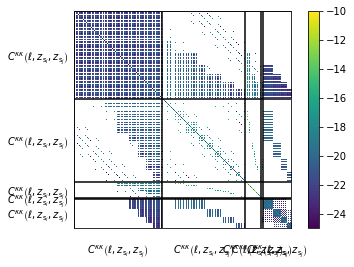

[   0. 1100. 2140. 2340. 2356. 2716.]


In [14]:
import sys
import os
import math, numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from numpy import linalg as LA
import numpy as np

nggl = 52 	# number of ggl power spectra
ngcl = 18	# number of cluster-source galaxy power spectra
nlens = 10 	# number of lens bins 
nlenscl= 4 	# number of cluster redshift bins 
nshear = 55 # number of shear tomographic power spectra
ncl=20		# number of ell-bins
nclgcl=5	# number of cluster ell-bins
nrich=4 	# number of richness bins


ndata = (nshear+nggl+nlens)*ncl+nlenscl*nrich+nrich*ngcl*nclgcl
n2pt = (nshear+nggl+nlens)*ncl 
ncluster = nlenscl*nrich 
n2ptcl=n2pt+ncluster
nclusterN_WL=ncluster+nrich*ngcl*nclgcl


outname="LSST_SRD"
datafile= np.genfromtxt("datav/LSST_3x2pt_clusterN_clusterWL_SRD")
mask = np.zeros(ndata)
for i in range(0,datafile.shape[0]):
    if (datafile[i,1] >1.0e-15): 
        mask[i]=1.0

k=0
covfile = np.genfromtxt("/users/timeifler/Dropbox/cosmolike_store/LSST_emu/cov_LSST_DESC_SRD_area1.420263e+04_ng2.700000e+01_nl4.800000e+01")
cov = np.ones((ndata,ndata))

print ndata,int(np.max(covfile[:,0])+1)

for i in range(0,covfile.shape[0]):
    cov[int(covfile[i,0]),int(covfile[i,1])] = covfile[i,8]+covfile[i,9]
    cov[int(covfile[i,1]),int(covfile[i,0])] = covfile[i,8]+covfile[i,9]

if 1. in cov[:, :]:
    print "Covariance assembly incomplete - covparallel file(s) missing"
else:
    print "Covariance assembly complete - all covparallel files present"

# numpyfile="/users/timeifler/Dropbox/cosmolike_store/LSST_emu/npcov/npcov_"+outname[k]
# np.save(numpyfile, cov)
# loadfile="/users/timeifler/Dropbox/cosmolike_store/LSST_emu/npcov/npcov_"+outname[k]+".npy"
# cov2=np.load(loadfile)
# print cov.shape, cov2.shape

cor = np.zeros((ndata,ndata))
for i in range(0,ndata):
    for j in range(0,ndata):
    	if (cov[i,i]*cov[j,j] >0):
       		cor[i,j] = cov[i,j]/math.sqrt(cov[i,i]*cov[j,j])


a = np.sort(LA.eigvals(cor[:,:]))
print "min+max eigenvalues full cor:"
print np.min(a), np.max(a)
print "neg eigenvalues full cor:"
for i in range(0,a.shape[0]):
	if (a[i]< 0.0): print a[i]


# ############### invert shear covariance #################
inv = LA.inv(cov[0:nshear*ncl,0:nshear*ncl])
a = np.sort(LA.eigvals(cov[0:nshear*ncl,0:nshear*ncl]))
print "min+max eigenvalues shear cov:"
print np.min(a), np.max(a)
outfile = outname+"_shear_shear_inv"
f = open(outfile, "w")
for i in range(0,nshear*ncl):
	inv[i,i]=inv[i,i]*mask[i]
  	for j in range(0,nshear*ncl):
  		f.write("%d %d %e\n" %(i,j, inv[i,j]))
f.close()


# ############### invert clustering covariance #################
inv = LA.inv(cov[(nshear+nggl)*ncl:(nshear+nggl+nlens)*ncl,(nshear+nggl)*ncl:(nshear+nggl+nlens)*ncl])
a = np.sort(LA.eigvals(cov[(nshear+nggl)*ncl:(nshear+nggl+nlens)*ncl,(nshear+nggl)*ncl:(nshear+nggl+nlens)*ncl]))
print "min+max eigenvalues clustering cov:"
print np.min(a), np.max(a)
outfile = outname+"_pos_pos_inv"
f = open(outfile, "w")
for i in range(0,nlens*ncl):
	inv[i,i]=inv[i,i]*mask[(nshear+nggl)*ncl+i]
	for j in range(0,nlens*ncl):
  		f.write("%d %d %e\n" %(i,j, inv[i,j]))
f.close()

# ############### invert 2pt covariance #################
a = np.sort(LA.eigvals(cov[0:n2pt,0:n2pt]))
print "min+max eigenvalues 2pt cov:"
print np.min(a), np.max(a)
inv = LA.inv(cov[0:n2pt,0:n2pt])
outfile = outname+"_3x2pt_inv" 
f = open(outfile, "w")
for i in range(0,n2pt):
	inv[i,i]=inv[i,i]*mask[i]
  	for j in range(0,n2pt):
  		f.write("%d %d %e\n" %( i,j, inv[i,j]))
f.close()



# # ############### invert full2pt+clusterN+clusterWL covariance #################
precond = 1.e-7
for i in range(0,ncluster):
    cov[n2pt+i,:]*= precond
    cov[:,n2pt+i]*= precond
inv = LA.inv(cov)
a = np.sort(LA.eigvals(cov))
print "min+max eigenvalues of full 2ptclusterN+clusterWL pre-conditioned matrix:"
print np.min(a), np.max(a)
if (np.min(a)<0):
    print "WARNING  WARNING: %s is not positive definite! WARNING!" % (covfile)
for i in range(0,ncluster):
    inv[n2pt+i,:]*= precond
    inv[:,n2pt+i]*= precond

outfile = outname+"_3x2pt_clusterN_clusterWL_inv"
f = open(outfile, "w")
for i in range(0,ndata):
    inv[i,i]=inv[i,i]*mask[i]
    for j in range(0,ndata):
        f.write("%d %d %e\n" %( i,j, inv[i,j]))
f.close()



# # ############### invert clusterN+clusterWL covariance #################
inv = LA.inv(cov[n2pt:n2pt+nclusterN_WL,n2pt:n2pt+nclusterN_WL])
a = np.sort(LA.eigvals(cov[n2pt:n2pt+nclusterN_WL,n2pt:n2pt+nclusterN_WL]))
print "min+max eigenvalues of clusterN_WL pre-conditioned matrix:"
print np.min(a), np.max(a)
if (np.min(a)<0):
    print "WARNING  WARNING: %s is not positive definite! WARNING!" % (covfile)

for i in range(0,ncluster):
    inv[i,:]*= precond
    inv[:,i]*= precond

outfile = outname+"_clusterN_clusterWL_inv"
f = open(outfile, "w")
for i in range(0,nclusterN_WL):
    inv[i,i]=inv[i,i]*mask[n2pt+i]
    for j in range(0,nclusterN_WL):
        f.write("%d %d %e\n" %( i,j, inv[i,j]))
f.close()

# # ############### invert clusterN covariance #################
inv = LA.inv(cov[n2pt:n2pt+ncluster,n2pt:n2pt+ncluster])
a = np.sort(LA.eigvals(cov[n2pt:n2pt+ncluster,n2pt:n2pt+ncluster]))
print "min+max eigenvalues of clusterN pre-conditioned matrix:"
print np.min(a), np.max(a)
if (np.min(a)<0):
    print "WARNING  WARNING: %s is not positive definite! WARNING!" % (covfile)

for i in range(0,ncluster):
    inv[i,:]*= precond
    inv[:,i]*= precond

outfile = outname+"_clusterN_inv"
f = open(outfile, "w")
for i in range(0,ncluster):
    inv[i,i]=inv[i,i]*mask[n2pt+i]
    for j in range(0,ncluster):
        f.write("%d %d %e\n" %( i,j, inv[i,j]))
f.close()


labels = (r'$C^{\kappa \kappa}\left(\ell,z_{\mathrm{s}_i},z_{\mathrm{s}_j}\right)$',r'$C^{\kappa \kappa}\left(\ell,z_{\mathrm{s}_i},z_{\mathrm{s}_j}\right)$',r'$C^{\kappa \kappa}\left(\ell,z_{\mathrm{s}_i},z_{\mathrm{s}_j}\right)$',r'$C^{\kappa \kappa}\left(\ell,z_{\mathrm{s}_i},z_{\mathrm{s}_j}\right)$',r'$C^{\kappa \kappa}\left(\ell,z_{\mathrm{s}_i},z_{\mathrm{s}_j}\right)$')
ticks = np.zeros(6)
tickx = np.zeros(5)
ticks[1] = nshear*ncl
ticks[2] = (nshear+nggl)*ncl
ticks[3] = n2pt
ticks[4] = n2pt+ncluster
ticks[5] = ndata

cor = np.zeros((ndata,ndata))
for i in range(0,ndata):
	for j in range(0,ndata):
		if (cov[i,i]*cov[j,j] >0):
			cor[i,j] = cov[i,j]/math.sqrt(cov[i,i]*cov[j,j])

fs= 10
for i in range(0,5):
		tickx[i] = 0.5*(ticks[i]+ticks[i+1])
		plt.plot([ticks[i]-0.5,ticks[i]-0.5],[-.5,ndata-0.5],linestyle ='-',color = 'k')
		plt.plot([-.5,ndata-0.5],[ticks[i]-0.5,ticks[i]-0.5],linestyle ='-',color = 'k')

plt.subplot(1, 1, 1)
ax = plt.gca()
im = ax.imshow(np.log10(cov[:,:]), interpolation="nearest",vmin=-25, vmax=-10)
plt.xticks(tickx, labels,fontsize=fs)
plt.yticks(tickx-0.5, labels,fontsize=fs)
plt.tick_params(axis = 'x',length = 0, pad = 15)
plt.tick_params(axis = 'y',length = 0, pad = 5)

plt.colorbar(im)
plt.show()

print ticks


# maskindices=np.where(mask == 0)[0]
# covnew=np.delete(cov, maskindices, 0)
# covcut=np.delete(covnew, maskindices, 1)
# covzero=np.where(covcut == 0)[0]

# plt.figure()
# plt.imshow(np.log10(np.abs(covcut[:,:])), interpolation="nearest",vmin=-25, vmax=-10)
# plt.colorbar()
# savefile="/users/timeifler/Dropbox/cosmolike_store/LSST_emu/plots/covcut_"+outname[k]+".png"
# plt.savefig(savefile, format='png', dpi=2000)


